# Episode 1: The mysterious rule of life

Conceived and written by Soeren Arlt at MPL, slightly updated by Florian Marquardt.

License: MIT (see the LICENSE file in the repository root).

## Basic information about the Game of Life

[Wikipedia](https://en.wikipedia.org/wiki/Conway%27s_Game_of_Life)

[Online simulator for Conway's game of life](https://playgameoflife.com/)

**list of interesting shapes** (as taken from Wikipedia)

| Still lifes | | Oscillators | | Spaceships | |
|---|---|---|---|---|---|
| Block | 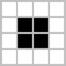 | Blinker (period 2) | 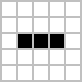 | Glider | 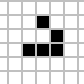 |
| Beehive | 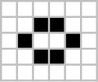 | Toad (period 2) | 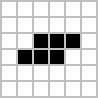 | Lightweight spaceship (LWSS) | 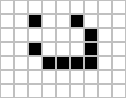 |
| Loaf | 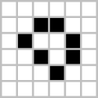 | Beacon (period 2) | 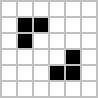 | Middleweight spaceship (MWSS) | 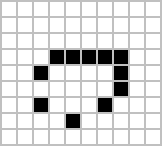 |
| Boat | 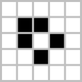 | Pulsar (period 3) | 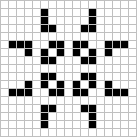 | Heavyweight spaceship (HWSS) | 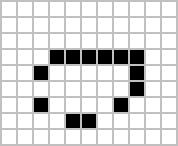 |
| Tub | 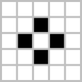 | Penta-decathlon (period 15) | 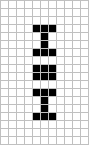 |  |  |

<small>Images from Wikimedia Commons. All are public domain except the tub ([Harsh Srivastava](https://commons.wikimedia.org/wiki/File:Game_of_life_flower.svg)), the penta-decathlon ([TastedWasted](https://commons.wikimedia.org/wiki/File:I-Column.gif)), and the MWSS and HWSS ([Maxgyisawesome](https://commons.wikimedia.org/wiki/File:Animated_Mwss.gif), [2](https://commons.wikimedia.org/wiki/File:Animated_Hwss.gif)), which are licensed under [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).</small>

## The scenario

Apparently, there has been a change in the rules of the universe, but at this moment it is still unknown what exactly has changed. You have to find out!

In [ ]:
# set gridsize (feel free to change, but big grid -> slower computation)
N = 20

### Defining the initial conditions

In [ ]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display


def grid():
    # Define a button click event
    def on_button_click(b):
        if b.style.button_color == 'gray':
            b.style.button_color = 'black'
        else:
            b.style.button_color = 'gray'


    grid = []
    for i in range(N):
        row = []
        for j in range(N):
            button = widgets.Button(description='',
                                    layout=widgets.Layout(width=f'{500 / N}px', height=f'{500 / N}px'),
                                    style=widgets.ButtonStyle(button_color='gray'))
            button.on_click(on_button_click)
            row.append(button)
        grid.append(row)

    grid_widget = widgets.VBox([widgets.HBox(row) for row in grid])
    display(grid_widget)

    # Function to convert the grid to numpy array
    def grid_to_numpy(b):
        global initial_array
        initial_array = np.zeros((N, N))
        for i in range(N):
            for j in range(N):
                if grid[i][j].style.button_color == 'black':
                    initial_array[i, j] = 1

    # Button to convert the grid to numpy array
    to_numpy_button = widgets.Button(description="Save as 'initial_array'",
                                     layout=widgets.Layout(width='auto', height='40px'))
    to_numpy_button.on_click(grid_to_numpy)

    display(to_numpy_button)

In [ ]:
# This cell displays an editor where you can
# draw the initial configuration
# Click the button below to save that configuration
# for use in the simulation!

grid()

## Simulation and Observation

In [ ]:
# This cell runs the simulation of
# both the normal game of life and the
# mysterious new version, based on 
# the initial configuration that you have
# drawn above

import numpy as np
from Episode1_life_helper import game_of_life, game_of_life_plus

# play with configuration given given by input widget above
Z0 = initial_array
Z1 = Z0.copy() # make copy to use for second simulation

# time steps (feel free to change, but more timesteps -> slower animation)
T = 50

# get simulation with known conway rules
Z_theory = game_of_life(Z0, T)
# get observation including the mystery change
Z_observation = game_of_life_plus(Z1,T)

In [ ]:
# This cell takes the results and turns
# them into a movie (it may take a bit of time)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, axs = plt.subplots(1, 3, figsize=(8,4))

for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])

def animate(i):
    axs[0].imshow(Z_theory[i], cmap='Greys')
    axs[1].imshow(Z_observation[i], cmap='Greys')
    axs[2].imshow(Z_theory[i]-Z_observation[i], cmap='Greys')

    axs[0].set_title('Conway simulation - Step ' + str(i))
    axs[1].set_title('Observation - Step ' + str(i))
    axs[2].set_title('Difference - Step ' + str(i))

ani = animation.FuncAnimation(fig, animate, frames=Z_theory.shape[0], interval=500)

HTML(ani.to_jshtml())